# How APEX gets its results
Data → chronological split → model comparison → frozen test → one live race prediction.
Run from the notebook's folder; all paths use the project root.

In [1]:
import os, warnings; warnings.filterwarnings('ignore')
os.chdir('..') if os.path.basename(os.getcwd())=='notebooks' else None
import sys; sys.path.insert(0, os.getcwd())
import pandas as pd, matplotlib.pyplot as plt
from src.config import load_config
cfg = load_config()

## 1. Data
One row per driver per race, with only pre-start features (grid, driver/constructor form, circuit history, weather).

In [2]:
df = pd.read_csv('data/processed/master_features.csv')
print(df.shape, df.season.min(), '-', df.season.max())
df[['season','race_name','driver_code','constructor_name','grid_position','driver_last5_avg_finish']].tail()

(25066, 91) 1950 - 2025


,season,race_name,driver_code,constructor_name,grid_position,driver_last5_avg_finish
25061,2025,Abu Dhabi Grand Prix,ALB,Williams,17.0,12.8
25062,2025,Abu Dhabi Grand Prix,HAD,RB F1 Team,9.0,12.2
25063,2025,Abu Dhabi Grand Prix,LAW,RB F1 Team,13.0,12.2
25064,2025,Abu Dhabi Grand Prix,GAS,Alpine F1 Team,19.0,14.6
25065,2025,Abu Dhabi Grand Prix,COL,Alpine F1 Team,20.0,15.4


## 2. Chronological split (no peeking at the future)

In [3]:
s = cfg['split']
print('train', s['train_start'], '-', s['train_end'], '| validation', s['validation_years'],
      '| CV folds', s['cv_validation_years'], '| locked test', s['test_years'])
df.groupby(df.season.map(lambda y: 'test' if y in s['test_years'] else 'validation' if y in s['validation_years'] else 'train')).race_id.nunique()

train 1950 - 2021 | validation [2022] | CV folds [2017, 2018, 2019, 2020, 2021] | locked test [2023, 2024, 2025]


season
test            70
train         1046
validation      22
Name: race_id, dtype: int64

## 3. Model comparison (validation, out-of-sample seasons)
Lower winner log-loss is better.

,label,family,winner_logloss,winner_top1,podium_overlap,rank_mae
0,Plackett–Luce ranking (simulator default),ranking,1.370,0.541,0.683,3.413
2,Logistic Regression,classification,1.426,0.541,0.672,3.421
13,Ridge Regression,regression,1.447,0.508,0.667,3.427
12,Linear Regression,regression,1.451,0.508,0.667,3.422
14,Lasso Regression,regression,1.455,0.508,0.672,3.437
16,Random Forest Regression,regression,1.467,0.508,0.672,3.395
7,Random Forest (decision forest),classification,1.470,0.525,0.672,3.546
4,K-Nearest Neighbours,classification,1.484,0.525,0.683,3.779
17,Gradient Boosting Regression,regression,1.496,0.508,0.683,3.402
8,Bagging (trees),classification,1.496,0.525,0.672,3.554


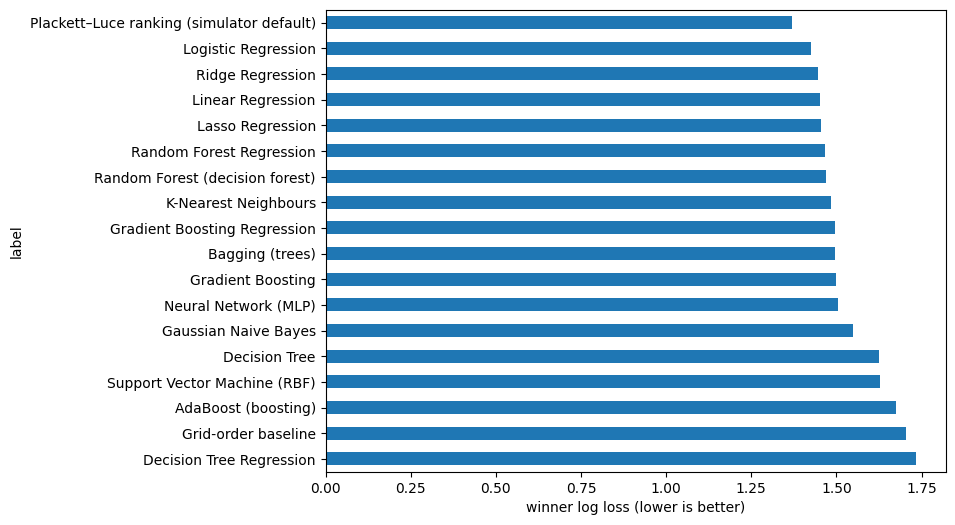

In [4]:
ac = pd.read_csv('outputs/tables/algorithm_comparison.csv')
t = ac.sort_values('winner_logloss')[['label','family','winner_logloss','winner_top1','podium_overlap','rank_mae']]
display(t.round(3))
ax = t.set_index('label').winner_logloss.sort_values().plot.barh(figsize=(8,6)); ax.invert_yaxis()
ax.set_xlabel('winner log loss (lower is better)'); plt.show()

## 4. Frozen test, 2023–2025
Model settings were fixed first; test races were scored once. Higher top-1 / overlap is better.

In [5]:
ft = pd.read_csv('outputs/tables/final_test_2023_2025_run1_frozen.csv')
display(ft[['model','races','winner_top1','winner_logloss','podium_overlap','rank_mae']].round(3))
rp = pd.read_csv('outputs/tables/live_pair_replay.csv')
display(rp[['model','races','winner_top1','winner_logloss','podium_overlap','rank_mae']].round(3))

,model,races,winner_top1,winner_logloss,podium_overlap,rank_mae
0,pl_linear_from1981_hl8,70,0.557,1.862,0.662,3.174
1,pl_grid,70,0.586,2.335,0.690,3.284
2,v1_classification_regression,70,0.643,1.106,0.662,3.099


,model,races,winner_top1,winner_logloss,podium_overlap,rank_mae
0,random_forest,70,0.586,1.127,0.690,3.259
1,ridge,70,0.600,1.143,0.690,3.214
2,logistic_regression,70,0.600,1.108,0.690,3.159
3,grid_baseline,70,0.586,1.376,0.690,3.284
4,default_pair,70,0.600,1.122,0.690,3.211
5,demo_pair,70,0.600,1.117,0.695,3.159


## 5. A live prediction
The `Predictor` uses models trained only on earlier seasons, then we reveal the actual result.

In [6]:
from src.predict import Predictor, race_summary
p = Predictor()
pred = p.predict_race(2022, 10)
display(pred[['pred_rank','driver_code','constructor_name','grid_position','win_prob','podium_prob']].sort_values('pred_rank').round(3))
race_summary(pred, p.actual_results(2022, 10))

,pred_rank,driver_code,constructor_name,grid_position,win_prob,podium_prob
0,1,VER,Red Bull,2.0,0.484,0.814
1,2,SAI,Ferrari,1.0,0.307,0.639
2,3,LEC,Ferrari,3.0,0.053,0.546
3,4,PER,Red Bull,4.0,0.042,0.354
4,5,HAM,Mercedes,5.0,0.057,0.237
5,6,RUS,Mercedes,8.0,0.032,0.151
6,7,NOR,McLaren,6.0,0.005,0.085
7,8,ALO,Alpine F1 Team,7.0,0.012,0.046
8,9,BOT,Alfa Romeo,12.0,0.002,0.018
9,10,OCO,Alpine F1 Team,15.0,0.000,0.009


{'predicted_podium': ['max_verstappen', 'sainz', 'leclerc'],
 'actual_podium': ['sainz', 'perez', 'hamilton'],
 'winner_correct': False,
 'podium_overlap': 1,
 'exact_podium': False,
 'spearman': 0.4857142857142857,
 'position_mae': 4.7,
 'actual_winner_win_prob': 0.30668621706037463}

**Caveat:** the 2023–2025 seasons were examined during development, so these scores are not independent accuracy on new races. See `README.md` for details.